# 🏀 NCAA Basketball Tournament Prediction

Este projeto tem como objetivo prever o resultado dos jogos do torneio de basquete da NCAA utilizando técnicas de Machine Learning.

A proposta segue a competição do Kaggle "March Machine Learning Mania 2025".

Autores:
- Aira Winner Sousa Ramos Torres
- Emanuel Victor Fonseca de Arauj

Criação: 04/2026

## Introdução

O Basquete da NCAA é uma competição entre times universitários que envolve as seguintes fases:<br>
1. **Temporada Regular** - fase de qualificação onde os times participam de vários jogos dentro de sua conferência.
2. **Torneio** - fase mata-mata em um chaveamento com os times mais bem pontuados da temporada regular 

O objetivo é prever o resultado dos confrontos do **Torneio**, estimando a **probabilidade de vitória de um time contra outro**.

## Importação de bibliotecas e configuração inicial

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import warnings

# Ignorando warnings para uma saída mais limpa
warnings.filterwarnings("ignore")
pd.set_option("display.max_column", 999)

# Os dados foram mantidos em um diretório chamado "data" no nível deste script
# Certificar-se de baixar os arquivos CSV do Kaggle e colocá-los nesse diretório para que o código funcione corretamente
DATA_PATH = "./data/"

## Tratamento dos dados

### Entendendo a tarefa

O esquema conceitual do modelo será:
- "_Dada as características do time A e as características do seu oponente B, qual será o resultado? (1=ganha, 0=perde)_"

Isto é, se a saída do modelo é o resultado de um jogo, a entrada são as características das equipes envolvidas neste confronto.


Porém, a dificuldade está no fato de que nos dados não são fornecidas as features prontas, como a força de cada time, mas apenas históricos e estatísticas dos jogos (lances livres tentados, rebotes defensivos, turnovers, etc).

<br> Portanto, a finalidade dessa etapa inicial será, com base nos jogos anteriores, **criar features para cada time** que descrevam seu desempenho, obtendo um dataset assim:
<style>
  table {
    border-collapse: collapse;
    width: 100%;
  }

  td, th {
    text-align: center;
  }
</style>
<table>
  <thead>
    <tr>
      <th colspan="8" style="text-align: center;">Conjunto de Features</th>
      <th rowspan="2" style="text-align: center;">Target</th>
    </tr>
    <tr>
      <th colspan="4" style="text-align: center;">Time A</th>
      <th colspan="4" style="text-align: center;">Time B</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>feature01</td>
      <td>feature02</td>
      <td>...</td>
      <td>featureN</td>
      <td>feature01</td>
      <td>feature02</td>
      <td>...</td>
      <td>featureN</td>
      <td>resultado_do_jogo</td>
    </tr>
  </tbody>
</table>

### Carregamento dos dados

No Kaggle são fornecidos diversos datasets, muitos dos quais contendo informações irelevantes, tal como formato da competição, localidades, etc.<br>
Logo, grande parte deles não serão utilizados.



Os dados pertinentes ao problema são:
- `RegularSeasonDetailedResults` - Resultados detalhados sobre cada jogo da temporada regular
- `NCAATourneyDetailedResults` - Resultados detalhados sobre cada jogo do torneio
- `NCAATourneySeeds` - Ranqueamento da equipe ao chegar na etapa do torneio definido pela pontuação que obteve na temporada regular

⚠️ Os datasets possuem prefixos (`M` e `W`) para indicar se a modalidade é Masculino ou Feminino, respectivamente.

In [2]:
# W -> Women, M -> Men
M_regular_results = pd.read_csv(f"{DATA_PATH}/MRegularSeasonDetailedResults.csv")
M_tourney_results = pd.read_csv(f"{DATA_PATH}/MNCAATourneyDetailedResults.csv")
M_seeds = pd.read_csv(f"{DATA_PATH}/MNCAATourneySeeds.csv")

W_regular_results = pd.read_csv(f"{DATA_PATH}/WRegularSeasonDetailedResults.csv")
W_tourney_results = pd.read_csv(f"{DATA_PATH}/WNCAATourneyDetailedResults.csv")
W_seeds = pd.read_csv(f"{DATA_PATH}/WNCAATourneySeeds.csv")

In [3]:
# Juntando os dados de homens e mulheres em um dataset só
regular_results = pd.concat([M_regular_results, W_regular_results])
tourney_results = pd.concat([M_tourney_results, W_tourney_results])
seeds = pd.concat([M_seeds, W_seeds])

### Filtragem mais atualizada

Por uma questão de conveniência, as métricas das equipes serão contabilizadas somente **a partir da temporada de 2003**, os últimos 21 anos, dado que as estatísticas detalhadas estão disponíveis a partir de então.

Esse recorte não terá impacto negativo, pois intuitivamente tem-se que a boa performance desempenhada muito no passado até poderia distorcer a avaliação da realidade atual de uma equipe. 

In [4]:
season = 2003
regular_results = regular_results.loc[regular_results["Season"] >= season]
tourney_results = tourney_results.loc[tourney_results["Season"] >= season]
seeds = seeds.loc[seeds["Season"] >= season]

### Preparação dos datasets

In [6]:

def prepare_data(df):
    """
    Função para criar um dataset com as estatísticas de ambos os times em cada jogo
    e a variável alvo "win" indicando se o time 1 venceu ou não
    """
    df = df[["Season", "DayNum", "LTeamID", "LScore", "WTeamID", "WScore", "NumOT",
            "LFGM", "LFGA", "LFGM3", "LFGA3", "LFTM", "LFTA", "LOR", "LDR", "LAst", "LTO", "LStl", "LBlk", "LPF",
            "WFGM", "WFGA", "WFGM3", "WFGA3", "WFTM", "WFTA", "WOR", "WDR", "WAst", "WTO", "WStl", "WBlk", "WPF"]]
    

    # Ajuste das estatíticas por tempo de jogo, dado que jogos com prorrogação têm mais tempo para acumular estatísticas
    adjot = (40 + 5 * df["NumOT"]) / 40 # Fator de proporção do tempo de jogo (40 minutos + 5 minutos por prorrogação)
    adjcols = ["LScore", "WScore", 
               "LFGM", "LFGA", "LFGM3", "LFGA3", "LFTM", "LFTA", "LOR", "LDR", "LAst", "LTO", "LStl", "LBlk", "LPF",
               "WFGM", "WFGA", "WFGM3", "WFGA3", "WFTM", "WFTA", "WOR", "WDR", "WAst", "WTO", "WStl", "WBlk", "WPF"]
    for col in adjcols:
        df[col] = df[col] / adjot    
    
    # Copiando o dataframe e criando uma versão "invertida" dos jogos, onde o time 1 é o time perdedor e o time 2 é o vencedor
    dfswap = df.copy()
    df.columns = [x.replace("W", "T1_").replace("L", "T2_") for x in list(df.columns)]
    dfswap.columns = [x.replace("L", "T1_").replace("W", "T2_") for x in list(dfswap.columns)]
    
    # Concatenando os dataframes para criar um dataset espelhado, onde cada jogo aparece duas vezes, 
    # uma vez com o time vencedor como time 1 e outra vez com o time perdedor como time 1
    output = pd.concat([df, dfswap]).reset_index(drop=True)

    # Criando features adicionais:
    output["PointDiff"] = output["T1_Score"] - output["T2_Score"] # diferença de pontos
    output["win"] = (output["PointDiff"] > 0) * 1                 # variável alvo: 1 se o time 1 venceu, 0 se perdeu
    output["men_women"] = (output["T1_TeamID"].apply(lambda t: str(t).startswith("1"))) * 1  # 0: women, 1: men
    
    return output

regular_data = prepare_data(regular_results)
tourney_data = prepare_data(tourney_results)

In [7]:
regular_data

,Season,DayNum,T2_TeamID,T2_Score,T1_TeamID,T1_Score,NumOT,T2_FGM,T2_FGA,T2_FGM3,T2_FGA3,T2_FTM,T2_FTA,T2_OR,T2_DR,T2_Ast,T2_TO,T2_Stl,T2_Blk,T2_PF,T1_FGM,T1_FGA,T1_FGM3,T1_FGA3,T1_FTM,T1_FTA,T1_OR,T1_DR,T1_Ast,T1_TO,T1_Stl,T1_Blk,T1_PF,PointDiff,win,men_women
0,2003,10,1328,62.0,1104,68.0,0,22.0,53.0,2.0,10.0,16.0,22.0,10.0,22.0,8.0,18.0,9.0,2.0,20.0,27.0,58.0,3.0,14.0,11.0,18.0,14.0,24.0,13.0,23.0,7.0,1.0,22.0,6.0,1,1
1,2003,10,1393,63.0,1272,70.0,0,24.0,67.0,6.0,24.0,9.0,20.0,20.0,25.0,7.0,12.0,8.0,6.0,16.0,26.0,62.0,8.0,20.0,10.0,19.0,15.0,28.0,16.0,13.0,4.0,4.0,18.0,7.0,1,1
2,2003,11,1437,61.0,1266,73.0,0,22.0,73.0,3.0,26.0,14.0,23.0,31.0,22.0,9.0,12.0,2.0,5.0,23.0,24.0,58.0,8.0,18.0,17.0,29.0,17.0,26.0,15.0,10.0,5.0,2.0,25.0,12.0,1,1
3,2003,11,1457,50.0,1296,56.0,0,18.0,49.0,6.0,22.0,8.0,15.0,17.0,20.0,9.0,19.0,4.0,3.0,23.0,18.0,38.0,3.0,9.0,17.0,31.0,6.0,19.0,11.0,12.0,14.0,2.0,18.0,6.0,1,1
4,2003,11,1208,71.0,1400,77.0,0,24.0,62.0,6.0,16.0,17.0,27.0,21.0,15.0,12.0,10.0,7.0,1.0,14.0,30.0,61.0,6.0,14.0,11.0,13.0,17.0,22.0,12.0,14.0,4.0,4.0,20.0,6.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
401175,2025,131,3471,75.0,3413,66.0,0,26.0,62.0,4.0,19.0,19.0,28.0,8.0,31.0,10.0,11.0,6.0,1.0,20.0,24.0,67.0,9.0,29.0,9.0,14.0,9.0,26.0,14.0,10.0,6.0,5.0,22.0,-9.0,0,0
401176,2025,132,3192,66.0,3476,49.0,0,23.0,55.0,3.0,21.0,17.0,18.0,10.0,22.0,11.0,9.0,8.0,1.0,8.0,21.0,57.0,4.0,20.0,3.0,4.0,14.0,22.0,14.0,17.0,4.0,1.0,17.0,-17.0,0,0
401177,2025,132,3250,74.0,3119,62.0,0,27.0,45.0,5.0,14.0,15.0,17.0,5.0,25.0,15.0,15.0,6.0,0.0,12.0,25.0,56.0,6.0,17.0,6.0,10.0,8.0,13.0,10.0,10.0,5.0,0.0,20.0,-12.0,0,0
401178,2025,132,3293,83.0,3125,62.0,0,28.0,54.0,14.0,28.0,13.0,15.0,5.0,33.0,21.0,13.0,2.0,3.0,15.0,24.0,68.0,2.0,21.0,12.0,14.0,12.0,22.0,11.0,7.0,5.0,0.0,16.0,-21.0,0,0


In [8]:
tourney_data

,Season,DayNum,T2_TeamID,T2_Score,T1_TeamID,T1_Score,NumOT,T2_FGM,T2_FGA,T2_FGM3,T2_FGA3,T2_FTM,T2_FTA,T2_OR,T2_DR,T2_Ast,T2_TO,T2_Stl,T2_Blk,T2_PF,T1_FGM,T1_FGA,T1_FGM3,T1_FGA3,T1_FTM,T1_FTA,T1_OR,T1_DR,T1_Ast,T1_TO,T1_Stl,T1_Blk,T1_PF,PointDiff,win,men_women
0,2003,134,1411,74.666667,1421,81.777778,1,25.777778,59.555556,10.666667,27.555556,12.444444,27.555556,15.111111,24.888889,14.222222,13.333333,4.444444,0.000000,19.555556,28.444444,61.333333,9.777778,25.777778,15.111111,23.111111,12.444444,26.666667,15.111111,10.666667,4.444444,2.666667,19.555556,7.111111,1,1
1,2003,136,1436,51.000000,1112,80.000000,0,20.000000,64.000000,4.000000,16.000000,7.000000,7.000000,8.000000,26.000000,12.000000,17.000000,10.000000,3.000000,15.000000,31.000000,66.000000,7.000000,23.000000,11.000000,14.000000,11.000000,36.000000,22.000000,16.000000,10.000000,7.000000,8.000000,29.000000,1,1
2,2003,136,1272,71.000000,1113,84.000000,0,25.000000,69.000000,7.000000,28.000000,14.000000,21.000000,20.000000,22.000000,11.000000,12.000000,2.000000,5.000000,18.000000,31.000000,59.000000,6.000000,14.000000,16.000000,22.000000,10.000000,27.000000,18.000000,9.000000,7.000000,4.000000,19.000000,13.000000,1,1
3,2003,136,1166,73.000000,1141,79.000000,0,27.000000,60.000000,7.000000,17.000000,12.000000,17.000000,14.000000,17.000000,20.000000,21.000000,6.000000,6.000000,21.000000,29.000000,53.000000,3.000000,7.000000,18.000000,25.000000,11.000000,20.000000,15.000000,18.000000,13.000000,1.000000,19.000000,6.000000,1,1
4,2003,136,1301,65.777778,1143,67.555556,1,22.222222,49.777778,8.000000,18.666667,13.333333,17.777778,8.888889,23.111111,14.222222,12.444444,4.444444,7.111111,16.888889,24.000000,56.888889,6.222222,17.777778,13.333333,20.444444,16.000000,17.777778,15.111111,11.555556,7.111111,1.777778,12.444444,1.777778,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4547,2024,147,3163,80.000000,3425,73.000000,0,28.000000,58.000000,7.000000,15.000000,17.000000,27.000000,5.000000,30.000000,17.000000,12.000000,6.000000,5.000000,21.000000,23.000000,70.000000,9.000000,29.000000,18.000000,20.000000,10.000000,25.000000,10.000000,9.000000,6.000000,4.000000,20.000000,-7.000000,0,0
4548,2024,147,3234,94.000000,3261,87.000000,0,32.000000,69.000000,13.000000,31.000000,17.000000,22.000000,3.000000,29.000000,16.000000,11.000000,6.000000,3.000000,15.000000,34.000000,88.000000,8.000000,24.000000,11.000000,17.000000,21.000000,28.000000,15.000000,13.000000,6.000000,6.000000,21.000000,-7.000000,0,0
4549,2024,151,3234,71.000000,3163,69.000000,0,27.000000,59.000000,7.000000,25.000000,10.000000,14.000000,9.000000,23.000000,12.000000,16.000000,7.000000,1.000000,9.000000,29.000000,63.000000,8.000000,25.000000,3.000000,4.000000,6.000000,22.000000,21.000000,14.000000,15.000000,1.000000,18.000000,-2.000000,0,0
4550,2024,151,3376,78.000000,3301,59.000000,0,33.000000,66.000000,8.000000,19.000000,4.000000,4.000000,10.000000,34.000000,18.000000,15.000000,10.000000,6.000000,16.000000,20.000000,62.000000,6.000000,23.000000,13.000000,18.000000,10.000000,18.000000,5.000000,12.000000,9.000000,1.000000,9.000000,-19.000000,0,0


#### Gerando feature: Seed da equipe

O número do *seed* é uma informação extremamente relevante, pois já representa uma avaliação prévia da força de cada time.

Antes do início da fase de Torneio NCAA, cada equipe recebe um *seed*, um número que representa sua posição no ranking dentro da chave, definido com base no seu desempenho ao longo da temporada, considerando fatores como vitórias, força dos adversários e consistência.

Esse valor geralmente vai de **1 a 16**, onde:
- **Seed 1** → times mais fortes (favoritos)
- **Seed 16** → times mais fracos (mais fracos)

Os prefixos **W**, **X**, **Y** e **Z** indicam as 4 regiões do torneio, informação que será desprezada.

In [9]:
# Extraindo o seed do campo "Seed", recortando apenas o número
seeds["seed"] = seeds["Seed"].apply(lambda x: int(x[1:3]))
seeds

,Season,Seed,TeamID,seed
1154,2003,W01,1328,1
1155,2003,W02,1448,2
1156,2003,W03,1393,3
1157,2003,W04,1257,4
1158,2003,W05,1280,5
...,...,...,...,...
1739,2025,Z12,3193,12
1740,2025,Z13,3251,13
1741,2025,Z14,3195,14
1742,2025,Z15,3117,15


In [10]:
# Extraindo o seed, a temporada e o ID do time, e duplicando para ter uma linha para cada time
seeds_T1 = seeds[["Season", "TeamID", "seed"]].copy()
seeds_T2 = seeds[["Season", "TeamID", "seed"]].copy()

# Renomeando as colunas para facilitar o merge com os dados dos jogos
seeds_T1.columns = ["Season", "T1_TeamID", "T1_seed"]
seeds_T2.columns = ["Season", "T2_TeamID", "T2_seed"]

# Fazendo o merge dos seeds com os dados dos jogos, para ter a informação do seed de ambos os times
tourney_data = tourney_data[["Season", "T1_TeamID", "T2_TeamID", "PointDiff", "win", "men_women"]]
tourney_data = pd.merge(tourney_data, seeds_T1, on=["Season", "T1_TeamID"], how="left")
tourney_data = pd.merge(tourney_data, seeds_T2, on=["Season", "T2_TeamID"], how="left")

# Criando uma feature de diferença de seed entre os times
tourney_data["Seed_diff"] = tourney_data["T2_seed"] - tourney_data["T1_seed"]

tourney_data

,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women,T1_seed,T2_seed,Seed_diff
0,2003,1421,1411,7.111111,1,1,16,16,0
1,2003,1112,1436,29.000000,1,1,1,16,15
2,2003,1113,1272,13.000000,1,1,10,7,-3
3,2003,1141,1166,6.000000,1,1,11,6,-5
4,2003,1143,1301,1.777778,1,1,8,9,1
...,...,...,...,...,...,...,...,...,...
4547,2024,3425,3163,-7.000000,0,0,1,3,2
4548,2024,3261,3234,-7.000000,0,0,3,1,-2
4549,2024,3163,3234,-2.000000,0,0,3,1,-2
4550,2024,3301,3376,-19.000000,0,0,3,1,-2


Verificando o quanto o *seed* está relacionado ao desempenho nas partidas

- Eixo x: *seed* do Time 1
- Eixo y: média da diferença de pontos

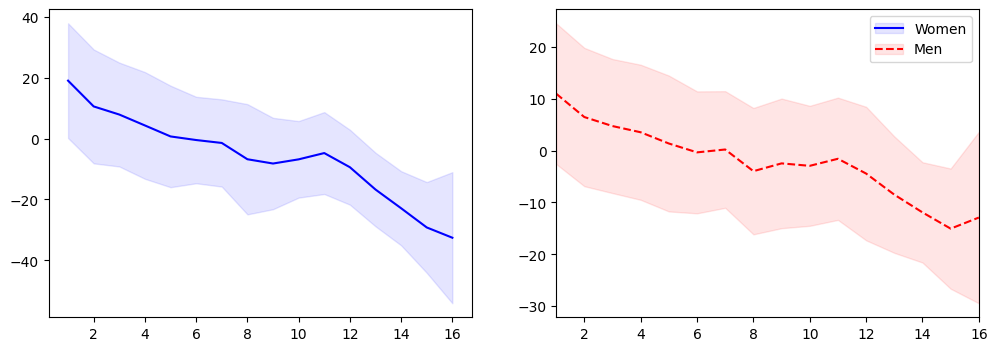

In [11]:
# Obtendo a diferença de pontos entre os times em função do seed, separando por homens e mulheres
tmpmean = tourney_data.pivot_table(columns="men_women", index="T1_seed", values="PointDiff", aggfunc="mean").ffill()
tmpstd = tourney_data.pivot_table(columns="men_women", index="T1_seed", values="PointDiff", aggfunc="std").ffill()

# Gráfico da diferença de pontos em função do seed, com barras de erro representando o desvio padrão
fig, axis = plt.subplots(ncols=2, figsize=(12, 4))
(line_1,) = axis[0].plot(tmpmean.index, tmpmean[0], "b-")
fill_1 = axis[0].fill_between(tmpmean.index, tmpmean[0] - tmpstd[0], tmpmean[0] + tmpstd[0], color="b", alpha=0.1)
(line_2,) = axis[1].plot(tmpmean.index, tmpmean[1], "r--")
fill_2 = axis[1].fill_between(tmpmean.index, tmpmean[1] - tmpstd[1], tmpmean[1] + tmpstd[1], color="r", alpha=0.1)
plt.margins(x=0)
plt.legend([(line_1, fill_1), (line_2, fill_2)], ["Women", "Men"])

Pelos gráficos é verificado que os melhores seeds (números menores) ficam com uma média de PointDiff positiva e mais alta, indicando um bom acúmulo de vitórias.

Percebe-se que o traço cai conforme o seed aumenta, isso indica que, como esperado, seeds piores tendem a ter mais derrotas, menor saldo de pontos.

Além disso, o desvio padrão, observado pela largura das faixas sombreadas, sugere que na categoria Feminino há uma incerteza maior na previsão dos jogos através do *seed* do que no Masculino, onde é encontrado um comportamento um pouco mais consistente.


#### Gerando features: Médias das estatísticas dos jogos

Outra métrica relevante são as estatísticas à nível de jogo de cada equipe na **Temporada Regular**

- **FGM** - pontuação de campo
- **FGA** - tentativas de pontos de campos
- **FGM3** - cesta de três pontos convertidas
- **FTM** - lances livres convertidos
- **FTA** - tentativas de lances livres
- **OR** - rebotes ofensivos
- **DR** - rebotes defensivos
- **AST** - assistências
- **Stl** - roubos de bola
- **Blk** - bloqueios
- **PF** - faltas pessoais


In [12]:
# Colunas de estatísticas dos jogos, separadas por time, para usar como features
boxcols = [
    "T1_Score", "T1_FGM", "T1_FGA", "T1_FGM3", "T1_FGA3", "T1_FTM", "T1_FTA",
    "T1_OR", "T1_DR", "T1_Ast", "T1_TO", "T1_Stl", "T1_Blk", "T1_PF",
    "T2_Score", "T2_FGM", "T2_FGA", "T2_FGM3", "T2_FGA3", "T2_FTM", "T2_FTA",
    "T2_OR", "T2_DR", "T2_Ast", "T2_TO", "T2_Stl", "T2_Blk", "T2_PF",
    "PointDiff",
]

Para todos os jogos de cada equipe nessa temporada, esses dados podem ser **agregados em uma média** e usados para predizer o resultado de uma partida no **Torneio** dessa mesma temporada.

In [13]:
# Calculando a média das estatísticas de cada time em cada temporada, para usar como features adicionais
ss = regular_data.groupby(["Season", "T1_TeamID"])[boxcols].agg("mean").reset_index()

# Criando dataframe separado para as estatísticas do time 1, renomeando as colunas das médias
ss_T1 = ss.copy()
ss_T1.columns = ["T1_avg_" + x.replace("T1_", "").replace("T2_", "opponent_") for x in list(ss_T1.columns)]
# Corrigindo os nomes das colunas de temporada e ID do time, que não se aplica como média
ss_T1 = ss_T1.rename({"T1_avg_Season": "Season", "T1_avg_TeamID": "T1_TeamID"}, axis=1)

ss_T2 = ss.copy()
ss_T2.columns = ["T2_avg_" + x.replace("T1_", "").replace("T2_", "opponent_") for x in list(ss_T2.columns)]
ss_T2 = ss_T2.rename({"T2_avg_Season": "Season", "T2_avg_TeamID": "T2_TeamID"}, axis=1)

# Fazendo o merge das estatísticas médias de ambos os times com os dados dos jogos
tourney_data = pd.merge(tourney_data, ss_T1, on=["Season", "T1_TeamID"], how="left")
tourney_data = pd.merge(tourney_data, ss_T2, on=["Season", "T2_TeamID"], how="left")

tourney_data

,Season,T1_TeamID,T2_TeamID,PointDiff,win,men_women,T1_seed,T2_seed,Seed_diff,T1_avg_Score,T1_avg_FGM,T1_avg_FGA,T1_avg_FGM3,T1_avg_FGA3,T1_avg_FTM,T1_avg_FTA,T1_avg_OR,T1_avg_DR,T1_avg_Ast,T1_avg_TO,T1_avg_Stl,T1_avg_Blk,T1_avg_PF,T1_avg_opponent_Score,T1_avg_opponent_FGM,T1_avg_opponent_FGA,T1_avg_opponent_FGM3,T1_avg_opponent_FGA3,T1_avg_opponent_FTM,T1_avg_opponent_FTA,T1_avg_opponent_OR,T1_avg_opponent_DR,T1_avg_opponent_Ast,T1_avg_opponent_TO,T1_avg_opponent_Stl,T1_avg_opponent_Blk,T1_avg_opponent_PF,T1_avg_PointDiff,T2_avg_Score,T2_avg_FGM,T2_avg_FGA,T2_avg_FGM3,T2_avg_FGA3,T2_avg_FTM,T2_avg_FTA,T2_avg_OR,T2_avg_DR,T2_avg_Ast,T2_avg_TO,T2_avg_Stl,T2_avg_Blk,T2_avg_PF,T2_avg_opponent_Score,T2_avg_opponent_FGM,T2_avg_opponent_FGA,T2_avg_opponent_FGM3,T2_avg_opponent_FGA3,T2_avg_opponent_FTM,T2_avg_opponent_FTA,T2_avg_opponent_OR,T2_avg_opponent_DR,T2_avg_opponent_Ast,T2_avg_opponent_TO,T2_avg_opponent_Stl,T2_avg_opponent_Blk,T2_avg_opponent_PF,T2_avg_PointDiff
0,2003,1421,1411,7.111111,1,1,16,16,0,69.615326,23.847510,55.639847,6.348659,17.658238,15.571648,20.428352,12.011494,22.652874,12.740230,15.931034,6.927969,2.937165,18.769349,76.947893,27.242146,59.712644,7.459004,20.307280,15.004598,22.157854,13.463602,22.401533,15.563218,12.568582,8.679693,4.141762,18.265134,-7.332567,72.533333,24.644444,55.051852,5.911111,18.437037,17.333333,27.929630,13.103704,24.677778,14.140741,15.166667,6.407407,2.222222,18.211111,70.585185,25.581481,60.140741,7.507407,23.051852,11.914815,18.655556,11.881481,22.781481,13.718519,14.259259,7.977778,2.596296,21.533333,1.948148
1,2003,1112,1436,29.000000,1,1,1,16,15,84.511905,30.067460,65.087302,6.984127,19.857143,17.392857,24.813492,15.051587,27.440476,17.488095,14.666667,8.396825,4.186508,17.587302,69.531746,26.115079,64.107143,6.253968,19.797619,11.047619,17.503968,12.980159,23.067460,15.341270,16.738095,5.904762,2.369048,21.888889,14.980159,67.255172,24.634483,55.427586,5.241379,15.310345,12.744828,19.379310,12.903448,25.565517,14.096552,13.993103,6.841379,2.958621,15.703448,62.565517,22.600000,54.696552,7.034483,21.344828,10.331034,15.482759,9.517241,21.641379,13.158621,12.910345,7.082759,3.655172,17.772414,4.689655
2,2003,1113,1272,13.000000,1,1,10,7,-3,75.344828,27.003831,56.436782,3.977011,12.475096,17.360153,25.877395,13.501916,23.111111,15.448276,13.881226,5.164751,4.191571,19.260536,68.574713,24.574713,55.176245,5.398467,15.766284,14.026820,20.375479,10.931034,20.367816,13.946360,15.402299,5.950192,3.908046,22.624521,6.770115,74.210728,26.183908,59.762452,6.969349,19.996169,14.873563,22.766284,14.019157,25.846743,16.555556,13.739464,7.363985,5.042146,18.693487,65.517241,23.164751,57.593870,5.854406,18.218391,13.333333,20.659004,12.295019,23.482759,13.237548,15.019157,7.252874,3.153257,19.827586,8.693487
3,2003,1141,1166,6.000000,1,1,11,6,-5,79.344828,26.620690,52.689655,6.827586,17.931034,19.275862,25.172414,10.586207,23.275862,15.620690,18.241379,7.103448,4.000000,20.965517,73.241379,26.344828,57.931034,4.965517,13.896552,15.586207,21.965517,12.241379,18.896552,11.793103,16.068966,8.448276,2.482759,21.689655,6.103448,79.006734,28.619529,57.289562,7.942761,20.424242,13.824916,19.952862,10.848485,23.097643,16.784512,13.309764,8.370370,4.427609,17.205387,64.107744,23.797980,55.148148,4.868687,14.282828,11.643098,16.619529,11.020202,21.289562,12.329966,17.006734,6.306397,2.569024,19.323232,14.898990
4,2003,1143,1301,1.777778,1,1,8,9,1,73.636015,27.015326,57.946360,6.314176,16.789272,13.291188,19.371648,11.114943,24.095785,15.816092,14.019157,6.455939,2.758621,16.888889,68.923372,25.072797,58.114943,7.034483,21.237548,11.743295,17.214559,11.049808,22.659004,15.881226,14.708812,5.865900,2.482759,18.919540,4.712644,72.122222,24.248148,53.129630,7.940741,22.429630,15.685185,20.385185,9.700000,21.907407,14.614815,14.129630,7.737037,3.048148,18.603704,67.751852,23.337037,52.925926,5.703704,16.903704,15.374074,21.129630,10.514815,21.348148,12.511111,14.581481,7.418519,2.811111,19.262963,4.370370

#### Gerando feature: Elo da equipe

O **Método de Avaliação por Elo** é um sistema que leva em conta os dados sequenciais dos jogos ao longo do tempo para criar uma métrica acumulada da força do time.

- Cada time começa com um elo incial
- Após cada jogo o valor do elo de cada um é atualizado

O **resultado esperado** de uma partida é obtido de um fórmula que calcula a probabilidade de A vencer B com base na diferença dos seus elos:

```py
1 / (1 + 10 ** ((elo_b - elo_a) / 400))
```

Quanto maior a diferença entre os elos, mais distante dos 0.5 este valor fica.

Com base nisso há a **mudança no elo** por jogo:

```py
change_in_elo = k_factor * (1 - expected_win)
```

Ou seja, um time que já tem alta chance de vencer o jogo tem pouca mudança quando vence,<br>
mas quando um time fraco (baixa expectativa de vitória) ganha um jogo, a mudança é elevada.

In [14]:
def update_elo(winner_elo, loser_elo):
    """ Função que calcula a atualização do Elo de ambos os times após um jogo """
    expected_win = expected_result(winner_elo, loser_elo)
    change_in_elo = k_factor * (1 - expected_win)
    winner_elo += change_in_elo
    loser_elo -= change_in_elo
    return winner_elo, loser_elo


def expected_result(elo_a, elo_b):
    """ Função que calcula a probabilidade de vitória do time 1 contra o time 2, dado o Elo de ambos os times """
    return 1.0 / (1 + 10 ** ((elo_b - elo_a) / elo_width))

base_elo = 1000   # Elo inicial para todos os times
elo_width = 400   # Parâmetro de controle da diferença de Elo
k_factor = 100    # Parâmetro de controle da magnitude da atualização do Elo após cada jogo


elos = []
for season in sorted(set(seeds["Season"])):  # Itera sobre as temporadas
    ss = regular_data.loc[regular_data["Season"] == season]
    ss = ss.loc[ss["win"] == 1].reset_index(drop=True) # Considerando apenas os jogos onde o time 1 venceu, para atualizar o Elo de ambos os times corretamente
    teams = set(ss["T1_TeamID"]) | set(ss["T2_TeamID"]) # Obtendo o conjunto de times que jogaram na temporada, para inicializar o Elo de cada time
    elo = dict(zip(teams, [base_elo] * len(teams))) # Inicializando o Elo de cada time com o valor base

    for i in range(ss.shape[0]):
        w_team, l_team = ss.loc[i, "T1_TeamID"], ss.loc[i, "T2_TeamID"] # Obtendo os IDs do time vencedor e perdedor do jogo
        w_elo, l_elo = elo[w_team], elo[l_team]   # Obtendo o Elo atual de ambos os times
        w_elo_new, l_elo_new = update_elo(w_elo, l_elo)  # Calculando o novo Elo de ambos os times após o jogo
        elo[w_team] = w_elo_new  # Atualizando o Elo do time vencedor
        elo[l_team] = l_elo_new  # Atualizando o Elo do time perdedor

    elo = pd.DataFrame.from_dict(elo, orient="index").reset_index()  # Convertendo o dicionário de Elo para um dataframe
    elo = elo.rename({"index": "TeamID", 0: "elo"}, axis=1)  # Renomeando as colunas do dataframe de Elo
    elo["Season"] = season    # Adicionando a coluna de temporada ao dataframe de Elo
    elos.append(elo)
    
elos = pd.concat(elos)  # Concatenando os dataframes de Elo de todas as temporadas em um único dataframe

# Incluindo o Elo de ambos os times como features adicionais no dataframe de dados dos jogos
elos_T1 = elos.copy().rename({"TeamID": "T1_TeamID", "elo": "T1_elo"}, axis=1)
elos_T2 = elos.copy().rename({"TeamID": "T2_TeamID", "elo": "T2_elo"}, axis=1)
tourney_data = pd.merge(tourney_data, elos_T1, on=["Season", "T1_TeamID"], how="left")
tourney_data = pd.merge(tourney_data, elos_T2, on=["Season", "T2_TeamID"], how="left")

# Criando uma feature adicional de diferença de Elo entre os times
tourney_data["elo_diff"] = tourney_data["T1_elo"] - tourney_data["T2_elo"]

#### Gerando feature: Qualidade da equipe

In [16]:
import statsmodels.api as sm
import tqdm

regular_data["ST1"] = regular_data.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T1_TeamID"])), axis=1)
regular_data["ST2"] = regular_data.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T2_TeamID"])), axis=1)
seeds_T1["ST1"] = seeds_T1.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T1_TeamID"])), axis=1)
seeds_T2["ST2"] = seeds_T2.apply(lambda t: str(int(t["Season"])) + "/" + str(int(t["T2_TeamID"])), axis=1)

# Coletando os times do torneio
st = set(seeds_T1["ST1"]) | set(seeds_T2["ST2"])
# Incluindo os times que conseguiram vencer um time do torneio pelo menos uma vez, mesmo que não tenham se classificado para o torneio
st = st | set(regular_data.loc[(regular_data["T1_Score"] > regular_data["T2_Score"]) & 
                                (regular_data["ST2"].isin(st)), "ST1"])



def team_quality(season, men_women):
    """
       Função que calcula a qualidade de cada time em uma temporada, 
       usando um modelo de regressão linear generalizada (GLM) 
       com efeitos mistos, onde o intercepto é fixo em 0 e o coeficiente 
       de cada time é um efeito aleatório que representa a qualidade do time.
    """
    # Efeitos mistos: intercepto fixo=0, random slope
    formula = "PointDiff~-1+T1_TeamID+T2_TeamID"
    glm = sm.GLM.from_formula(
        formula=formula,
        data=dt.loc[(dt["Season"] == season) & (dt["men_women"] == men_women), :],
        family=sm.families.Gaussian(),
    ).fit()
    
    quality = pd.DataFrame(glm.params).reset_index()
    quality.columns = ["TeamID", "quality"]
    quality["quality"] = quality["quality"]
    quality["Season"] = season
    quality = quality.loc[quality.TeamID.str.contains("T1_")].reset_index(drop=True)
    quality["TeamID"] = quality["TeamID"].apply(lambda x: x[10:14]).astype(int)
    return quality


glm_quality = []

dt = regular_data.loc[regular_data["ST1"].isin(st) | regular_data["ST2"].isin(st)]
dt["T1_TeamID"] = dt["T1_TeamID"].astype(str)
dt["T2_TeamID"] = dt["T2_TeamID"].astype(str)
dt.loc[~dt["ST1"].isin(st), "T1_TeamID"] = "0000"
dt.loc[~dt["ST2"].isin(st), "T2_TeamID"] = "0000"
seasons = sorted(set(seeds["Season"]))
for s in tqdm.tqdm(seasons, unit="season"):
    if s >= 2010:  # Temporada mínima para mulheres, de acordo com a disponibilidade de dados
        glm_quality.append(team_quality(s, 0))
    if s >= 2003:  # Temporada mínima para homens
        glm_quality.append(team_quality(s, 1))

glm_quality = pd.concat(glm_quality).reset_index(drop=True)

# Incluindo a qualidade de ambos os times como features adicionais no dataframe de dados dos jogos
glm_quality_T1 = glm_quality.copy()
glm_quality_T2 = glm_quality.copy()
glm_quality_T1.columns = ["T1_TeamID", "T1_quality", "Season"]
glm_quality_T2.columns = ["T2_TeamID", "T2_quality", "Season"]
tourney_data = pd.merge(tourney_data, glm_quality_T1, on=["Season", "T1_TeamID"], how="left")
tourney_data = pd.merge(tourney_data, glm_quality_T2, on=["Season", "T2_TeamID"], how="left")

# Criando uma feature adicional de diferença de qualidade entre os times
tourney_data["diff_quality"] = tourney_data["T1_quality"] - tourney_data["T2_quality"]

100%|██████████| 22/22 [00:57<00:00,  2.64s/season]


## Treinamento do Modelo de Predição

In [17]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

TODO: Avaliar o que é o `GridSearchCV` e o `Optuna` para fazer a **Avaliação de Parâmetros**

In [18]:

features = [
    ### EASY FEATURES ###
    "men_women",    
    "T1_seed",
    "T2_seed",
    "Seed_diff",
    ### MEDIUM FEATURES ###
    "T1_avg_Score",
    #"T1_avg_FGM",
    "T1_avg_FGA",
    #"T1_avg_FGM3",
    #"T1_avg_FGA3",
    #"T1_avg_FTM",
    #"T1_avg_FTA",
    "T1_avg_OR",
    "T1_avg_DR",
    #"T1_avg_Ast",
    #"T1_avg_TO",
    #"T1_avg_Stl",
    "T1_avg_Blk",
    "T1_avg_PF",
    #"T1_avg_opponent_Score",
    #"T1_avg_opponent_FGM",
    "T1_avg_opponent_FGA",
    #"T1_avg_opponent_FGM3",
    #"T1_avg_opponent_FGA3",
    #"T1_avg_opponent_FTM",
    #"T1_avg_opponent_FTA",
    #"T1_avg_opponent_OR",
    #"T1_avg_opponent_DR",
    #"T1_avg_opponent_Ast",
    #"T1_avg_opponent_TO",
    #"T1_avg_opponent_Stl",
    "T1_avg_opponent_Blk",
    "T1_avg_opponent_PF",
    "T1_avg_PointDiff",
    "T2_avg_Score",
    #"T2_avg_FGM",
    "T2_avg_FGA",
    #"T2_avg_FGM3",
    #"T2_avg_FGA3",
    #"T2_avg_FTM",
    #"T2_avg_FTA",
    "T2_avg_OR",
    "T2_avg_DR",
    #"T2_avg_Ast",
    #"T2_avg_TO",
    #"T2_avg_Stl",
    "T2_avg_Blk",
    "T2_avg_PF",
    #"T2_avg_opponent_Score",
    #"T2_avg_opponent_FGM",
    "T2_avg_opponent_FGA",
    #"T2_avg_opponent_FGM3",
    #"T2_avg_opponent_FGA3",
    #"T2_avg_opponent_FTM",
    #"T2_avg_opponent_FTA",
    #"T2_avg_opponent_OR",
    #"T2_avg_opponent_DR",
    #"T2_avg_opponent_Ast",
    #"T2_avg_opponent_TO",
    #"T2_avg_opponent_Stl",
    "T2_avg_opponent_Blk",
    "T2_avg_opponent_PF",
    "T2_avg_PointDiff",
    ### HARD FEATURES ###
    "T1_elo",
    "T2_elo",    
    "elo_diff",
    ### HARDEST FEATURES ###
    "T1_quality",
    "T2_quality",
]

print(f"Number of features {len(features)}")

Number of features 29


In [19]:
# Seleção final
X = tourney_data[features]
y = tourney_data['win']

Calculando o baseline

In [20]:
# Função de cálculo da métrica (Brier Score)
def brier_score(y_true, y_prob):
    return np.mean((y_prob - y_true) ** 2)

# Baseline
baseline_preds = np.full(len(y), 0.5)
print("Baseline Brier Score:", brier_score(y, baseline_preds))

Baseline Brier Score: 0.25


Treinamento e Avaliação dos Modelos de Predição com Validação Cruzada

In [ ]:
# Modelos
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=100)
}

kf = KFold(n_splits=10, shuffle=True, random_state=42)

for name, model in models.items():
    scores = []

    for train_idx, val_idx in tqdm.tqdm(kf.split(X), total=kf.get_n_splits()):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, y_train)
        probs = model.predict_proba(X_val)[:,1]

        score = brier_score(y_val, probs)
        scores.append(score)

    print(f"{name} - Brier Score médio: {np.mean(scores)}\n")

100%|██████████| 10/10 [00:02<00:00,  4.26it/s]


LogisticRegression - Brier Score médio: 0.16847156986180473


100%|██████████| 10/10 [00:08<00:00,  1.14it/s]

RandomForest - Brier Score médio: 0.1764692983420089


In [ ]:

# Ensemble (Meta-learning simples)
model1 = LogisticRegression(max_iter=1000)
model2 = RandomForestClassifier(n_estimators=100)

model1.fit(X, y)
model2.fit(X, y)

probs1 = model1.predict_proba(X)[:,1]
probs2 = model2.predict_proba(X)[:,1]

ensemble_probs = (probs1 + probs2) / 2

print("Ensemble Brier Score:", brier_score(y, ensemble_probs))


# 8. Próximos passos
# - Testar XGBoost / LightGBM
# - Fazer split temporal (treino até 2024, teste 2025)
